In [279]:
import numpy as np
import matplotlib.pyplot as plt

In [280]:
def power_method(A, x0, tol=0.5e-6, max_iter=100):
  x = x0.copy()
  lambda_old = 0
  errors = []
  for k in range(max_iter):
    x = np.dot(A, x)
    x = x / np.linalg.norm(x)
    lambda_new = np.dot(x.T, np.dot(A, x))
    error = abs(lambda_new - lambda_old)
    errors.append(error)
    if error < tol:
      break
    lambda_old = lambda_new
  return lambda_new, x, errors

In [281]:
def inverse_power_method(A, x0, tol=0.5e-6, max_iter=100):
  x = x0.copy()
  lambda_old = 0
  errors = []
  A_inv = np.linalg.inv(A)
  for k in range(max_iter):
    x = np.dot(A_inv, x)
    x = x / np.linalg.norm(x)
    lambda_new = np.dot(x.T, np.dot(A, x))
    error = abs(lambda_new - lambda_old)
    errors.append(error)
    if error < tol:
      break
    lambda_old = lambda_new
  return 1/lambda_new, x, errors

In [282]:
def plot_errors(errors, method):
  plt.figure(figsize=(8, 5))
  plt.plot(range(1, len(errors)+1), errors, marker='o', linestyle='-', label=f'Error ({method})')
  plt.yscale('log')
  plt.xlabel('Iteration')
  plt.ylabel('Error (log scale)')
  plt.title(f'Error Decay in {method} Method')
  plt.legend()
  plt.grid(True)
  plt.show()

In [283]:
# Example Usage
# A = np.array([[4, 1], [2, 3]], dtype=float)
# x0 = np.array([1, 1], dtype=float)
A = np.array([[.5, 0, 0],
              [2, 2, 0],
              [-4, 1, -1.5]], dtype=float)
x0 = np.array([1, 1, 1], dtype=float)

Power Method Eigenvalue:  1.99999978700314


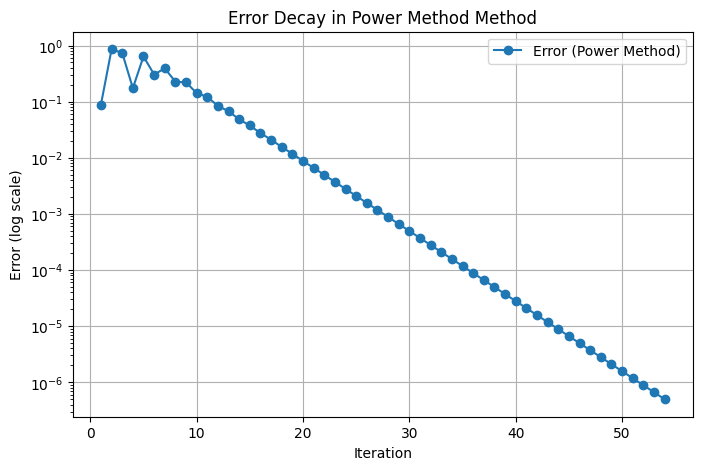

In [284]:
# Power Method
lambda_power, eigenvector_power, errors_power = power_method(A, x0)
print("Power Method Eigenvalue: ", lambda_power)
plot_errors(errors_power, "Power Method")

Inverse Power Method Eigenvalue:  2.000000453801206


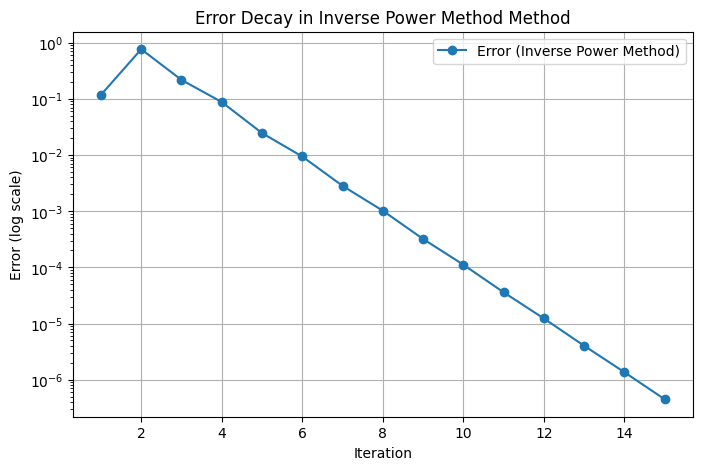

In [285]:
# Inverse Power Method
lambda_inverse, eigenvector_inverse, errors_inverse = inverse_power_method(A, x0)
print("Inverse Power Method Eigenvalue: ", lambda_inverse)
plot_errors(errors_inverse, "Inverse Power Method")